**Q2. Efficient Frontier and CML**

(a) Basic Stats

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv('crsp_sample.csv')
df['date'] = pd.to_datetime(df['date'])
df = df[(df['date'] >= '2022-01-01') & (df['date'] <= '2023-12-31')]

permnos = [39731, 79089, 83148]
df = df[df['permno'].isin(permnos)]

returns = df.pivot(index='date', columns='permno', values='ret')
returns = returns.dropna()
returns = returns[permnos]

#print(f"\nNumber of trading days: {len(returns)}")
#print(f"\nMissing values:\n{returns.isnull().sum()}")

mean_daily = returns.mean()
std_daily = returns.std()
cov_matrix = returns.cov()
corr_matrix = returns.corr()

print("Mean Daily Returns:\n", mean_daily)
print("\nDaily Standard Deviation:\n", std_daily)
print("\nDaily Covariance Matrix:\n", cov_matrix)
print("\nDaily Correlation Matrix:\n", corr_matrix)

Mean Daily Returns:
 permno
39731   -0.000407
79089   -0.002484
83148    0.000822
dtype: float64

Daily Standard Deviation:
 permno
39731    0.045244
79089    0.051850
83148    0.061252
dtype: float64

Daily Covariance Matrix:
 permno     39731     79089     83148
permno                              
39731   0.002047  0.000373  0.000179
79089   0.000373  0.002688  0.000399
83148   0.000179  0.000399  0.003752

Daily Correlation Matrix:
 permno     39731     79089     83148
permno                              
39731   1.000000  0.159089  0.064644
79089   0.159089  1.000000  0.125509
83148   0.064644  0.125509  1.000000


(b) Annualize (*252 days)

In [ ]:
mean_annual = mean_daily * 252
std_annual = std_daily * np.sqrt(252)
cov_annual = cov_matrix * 252

print("Annual Return:\n", mean_annual)
print("\nAnnual Standard Deviation:\n", std_annual)
print("\nAnnual Covariance:\n", cov_annual)
print("\nAnnual Correlation:\n", corr_matrix) #dimensionless

Annual Return:
 permno
39731   -0.102641
79089   -0.626013
83148    0.207042
dtype: float64

Annual Standard Deviation:
 permno
39731    0.718220
79089    0.823088
83148    0.972350
dtype: float64

Annual Covariance:
 permno     39731     79089     83148
permno                              
39731   0.515840  0.094047  0.045145
79089   0.094047  0.677474  0.100449
83148   0.045145  0.100449  0.945464

Annual Correlation:
 permno     39731     79089     83148
permno                              
39731   1.000000  0.159089  0.064644
79089   0.159089  1.000000  0.125509
83148   0.064644  0.125509  1.000000


(c) Portfolio Construction and Analysis

In [ ]:
def port_return(weights, mean_returns):
    return np.sum(weights*mean_returns)

def port_vol(weights, cov_matrix):
    return np.sqrt(np.dot(weights.T, np.dot(cov_matrix, weights)))

w1 = np.array([0.4, 0.2, 0.4])
w2 = np.array([0.8, 0.1, 0.1])

# portfolio 1
r1 = port_return(w1, mean_annual)
v1 = port_vol(w1, cov_annual)

# portfolio 2
r2 = port_return(w2, mean_annual)
v2 = port_vol(w2, cov_annual)

print("Portfolio 1 Avg Return:", r1)
print("Portfolio 1 Standard Deviation:", v1)

print("Portfolio 2 Avg Return:", r2)
print("Portfolio 2 Standard Deviation:", v2)

Portfolio 1 Avg Return: -0.08344217964071851
Portfolio 1 Standard Deviation: 0.553600246813381
Portfolio 2 Avg Return: -0.12400985389221565
Portfolio 2 Standard Deviation: 0.6088074761828386


(d) Efficient Frontier

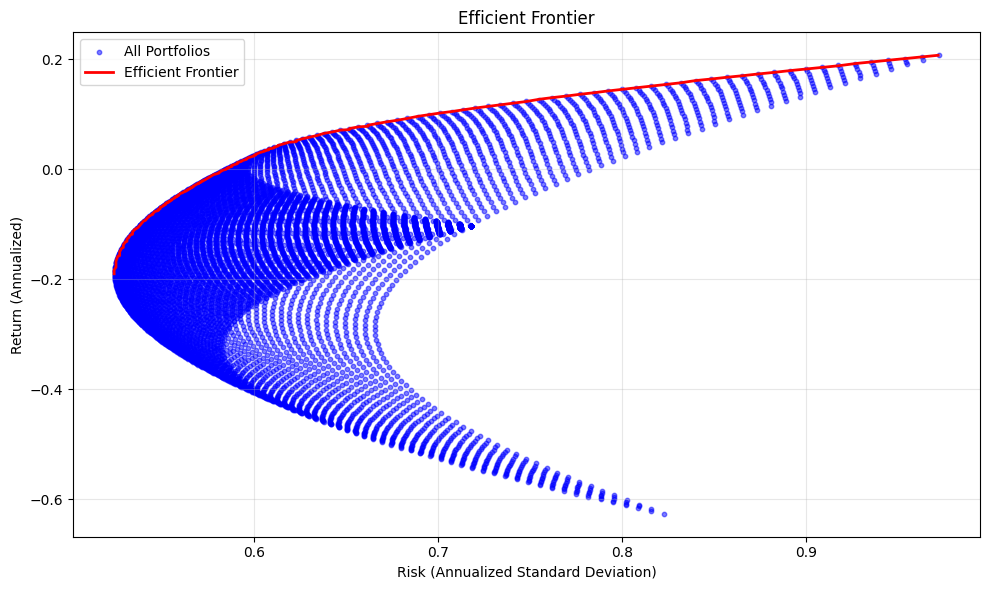

In [ ]:
weights_list = []
returns_list = []
vol_list = []

for w1 in np.linspace(0, 1, 101):
    for w2 in np.linspace(0, 1 - w1, 101):
        w3 = 1 - w1 - w2
        if w3 >= 0:
            weights = np.array([w1, w2, w3])

            ret = port_return(weights, mean_annual)
            vol = port_vol(weights, cov_annual)

            weights_list.append(weights)
            returns_list.append(ret)
            vol_list.append(vol)

returns_arr = np.array(returns_list)
vol_arr = np.array(vol_list)

# all portfolios
plt.figure(figsize=(10, 6))
plt.scatter(vol_arr, returns_arr, alpha=0.5, s=10, c='blue', label='All Portfolios')

returns_rounded = np.round(returns_arr, 3)
vol_rounded = np.round(vol_arr, 3)

# highlight the efficient frontier
# sort by volatility, keep max return for each volatility
sorted_indices = np.argsort(vol_rounded)
vol_sorted = vol_rounded[sorted_indices]
ret_sorted = returns_rounded[sorted_indices]

#keep only the upper part
efficient_vol = []
efficient_ret = []
max_ret = -np.inf
for v, r in zip(vol_sorted, ret_sorted):
    if r > max_ret:
        efficient_vol.append(v)
        efficient_ret.append(r)
        max_ret = r
plt.plot(efficient_vol, efficient_ret, 'r-', linewidth=2, label='Efficient Frontier')

plt.xlabel("Risk (Annualized Standard Deviation)")
plt.ylabel("Return (Annualized)")
plt.title("Efficient Frontier")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

(e) Maximum Sharpe Ratio and CML

In [ ]:
# sharpe ratios
sharpe_ratios = np.array(returns_list) / np.array(vol_list)

# find max sharpe ratio portfolio
max_idx = np.argmax(sharpe_ratios)
optimal_weights = weights_list[max_idx]
optimal_return = returns_list[max_idx]
optimal_vol = vol_list[max_idx]
max_sharpe = sharpe_ratios[max_idx]

print("Optimal weights:", optimal_weights)
print("Return:", round(optimal_return, 3))
print("Standard Deviation:", round(optimal_vol, 3))
print("Sharpe:", round(max_sharpe, 3))

Optimal weights: [0. 0. 1.]
Return: 0.207
Standard Deviation: 0.972
Sharpe: 0.213


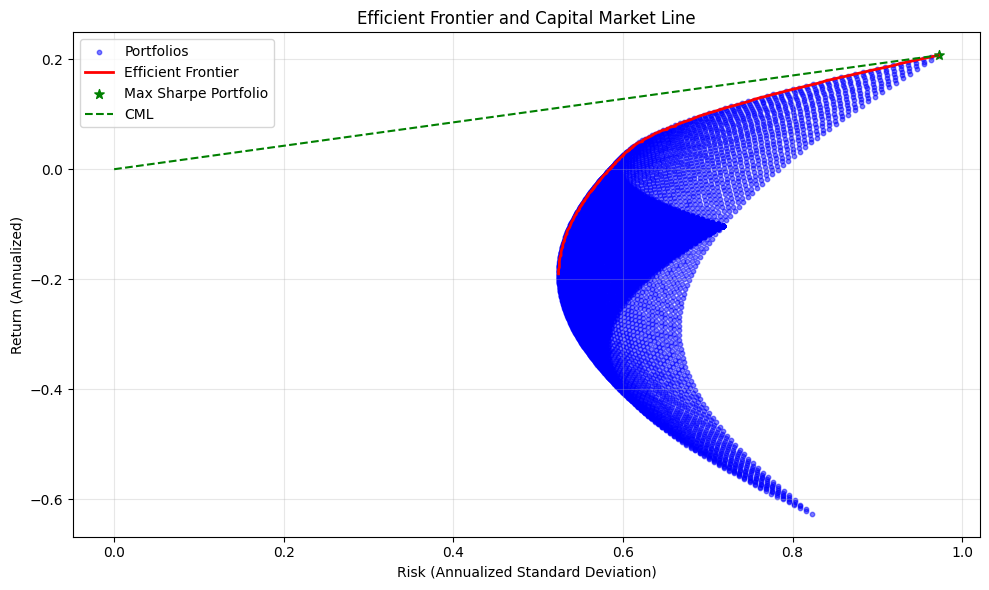

In [ ]:
plt.figure(figsize=(10, 6))
plt.scatter(vol_list, returns_list, alpha=0.5, s=10, label="Portfolios", color='blue')

# highlight ef
plt.plot(efficient_vol, efficient_ret, 'r-', linewidth=2, label='Efficient Frontier')

# highlight max sharpe portfolio
plt.scatter(optimal_vol, optimal_return, color='green', s=50, marker='*', label='Max Sharpe Portfolio')

# plot the cml
x = np.linspace(0, max(vol_list), 100)
y = max_sharpe * x
plt.plot(x, y, 'g--', label="CML")

plt.xlabel("Risk (Annualized Standard Deviation)")
plt.ylabel("Return (Annualized)")
plt.title("Efficient Frontier and Capital Market Line")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()